In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# Split features and target
X = df_imputed.drop(columns=['target'])
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")  # Corrected f-string with closing quote and value

# SHAP explanation
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values
imputer = SimpleImputer(strategy='mean')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# Split features and target
X = df_imputed.drop(columns=['target'])
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'n_estimators': [100, 200,300, 500, 750, 1000],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)

In [4]:
## LR AUC-RoC with all parameters

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (required for Logistic Regression)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']  # liblinear supports l1 and l2 penalties
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
explainer = shap.LinearExplainer(best_model, X_train)
shap_values = explainer.shap_values(X_test)

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_values, X_test)

In [6]:
## NB

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency with preprocessing)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'var_smoothing': np.logspace(0, -9, num=10)  # Range of var_smoothing values
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(GaussianNB(), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
# Wrapper function to return only the probability of the positive class
def model_predict_proba_positive(X):
    return best_model.predict_proba(X)[:, 1]

# Use the wrapper function with KernelExplainer
explainer = shap.KernelExplainer(model_predict_proba_positive, X_train)
shap_values = explainer.shap_values(X_test) # This will now be (num_samples, num_features)

# Since we wrapped predict_proba to return only the positive class, shap_values is already the array for the positive class
shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    # This line should ideally not be needed after the fix, but keeping it for debugging if needed
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)

In [8]:
## Bagging

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'n_estimators': [10, 50, 100],
    'max_samples': [0.5, 0.75, 1.0]
}
base_estimator = DecisionTreeClassifier(random_state=42)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(BaggingClassifier(base_estimator, random_state=42), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
# Use KernelExplainer for BaggingClassifier
explainer = shap.KernelExplainer(best_model.predict_proba, X_train)
shap_values = explainer.shap_values(X_test)

# KernelExplainer for binary classification with predict_proba returns shap_values for each class
# We are interested in the SHAP values for the positive class (index 1)
shap_array = shap_values[1] if isinstance(shap_values, list) and len(shap_values) > 1 else shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape (KernelExplainer often returns 2D even for single class)
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)

In [10]:
## Gradient Boost

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)

In [12]:
## XGBoost

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from xgboost import XGBClassifier # Import XGBoost
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# --- XGBoost Implementation ---
# Define the parameter grid for XGBoost
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0],  # Adding subsample for more thorough tuning
    'colsample_bytree': [0.8, 1.0] # Adding colsample_bytree for more thorough tuning
}

# Grid search with 10-fold CV for XGBoost
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'),
                    param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
# The TreeExplainer works directly with the XGBoost model
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)


In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7]
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'), param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)

In [15]:
## Adaboost

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier # Import AdaBoost
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# --- AdaBoost Implementation ---
# Define the parameter grid for AdaBoost
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 1.0],
}

# Grid search with 10-fold CV for AdaBoost
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(AdaBoostClassifier(random_state=42),
                    param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
# For AdaBoostClassifier, use KernelExplainer as TreeExplainer does not support it directly.
# KernelExplainer requires a background dataset. Using a sampled subset of X_train for efficiency.
explainer = shap.KernelExplainer(best_model.predict_proba, shap.sample(X_train, 100)) # Use a sample of X_train for background
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
# KernelExplainer with predict_proba for binary classification typically returns a 3D array:
# (num_samples, num_features, num_classes)
if isinstance(shap_values, list):
    # This branch might be hit if the explainer returns a list of 2D arrays (e.g., TreeExplainer)
    shap_array = shap_values[1] # SHAP values for the positive class
else:
    # This branch is for KernelExplainer on predict_proba, where shap_values is a 3D array.
    # We need to select the SHAP values for the positive class (index 1) across all samples and features.
    shap_array = shap_values[:, :, 1]

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape (should already be 1D if shap_array is correctly (samples, features))
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)


In [ ]:
## LGBM

[LightGBM] [Info] Number of positive: 239, number of negative: 90
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000098 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 861
[LightGBM] [Info] Number of data points in the train set: 329, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.726444 -> initscore=0.976654
[LightGBM] [Info] Start training from score 0.976654
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[L

/usr/local/lib/python3.12/dist-packages/shap/explainers/_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(



Top 5 Most Important Features (SHAP):
           Feature  Mean |SHAP value|
0           N_Days           0.523408
16  Hepatomegaly_Y           0.290565
9        Platelets           0.162784
8    Tryglicerides           0.159778
1              Age           0.155053


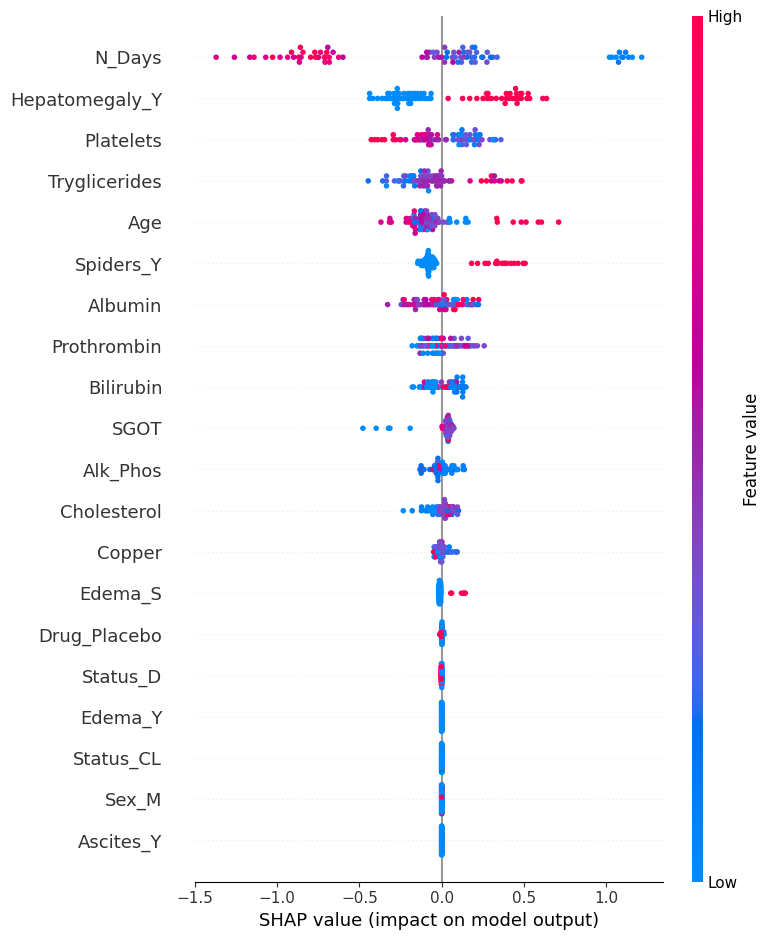

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier # Import LightGBM
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# --- LightGBM Implementation ---
# Define the parameter grid for LightGBM
# 'num_leaves' is a key parameter that controls the complexity of the trees
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'num_leaves': [31, 50, 100]
}

# Grid search with 10-fold CV for LightGBM
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(LGBMClassifier(random_state=42),
                    param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
# The TreeExplainer works directly with the LightGBM model
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)


In [20]:
##Catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.5 MB/s eta 0:00:00
Best parameters: {'depth': 7, 'iterations': 200, 'learning_rate': 0.01}
Best cross-validated AUC-ROC: 0.7456
GridSearchCV 5-fold AUC-ROC scores: [0.75578704 0.7025463  0.61805556 0.75115741 0.68865741 0.62615741
 0.74189815 0.67824074 0.66319444 0.75347222 0.71296296 0.65972222
 0.74421296 0.67592593 0.69212963 0.72685185 0.67592593 0.70023148
 0.74652778 0.67592593 0.68171296 0.75       0.68634259 0.70949074
 0.73263889 0.67708333 0.69907407 0.72106481 0.69097222 0.65509259
 0.70949074 0.67013889 0.60185185 0.70138889 0.64699074 0.59953704
 0.70717593 0.72800926 0.66550926 0.69097222 0.69560185 0.66435185
 0.69675926 0.67361111 0.64467593 0.68287037 0.70486111 0.63541667
 0.7037037  0.69560185 0.6400463  0.69675926 0.67361111 0.64814815
 0.78935185 0.79050926 0.74768519 0.79976852 0.79282407 0.76041667
 0.80902778 0.78935185 0.7974537  0.78703704 0.79050926 0.78240741
 0.7974537  0.78472222 0.81712963 0.8078

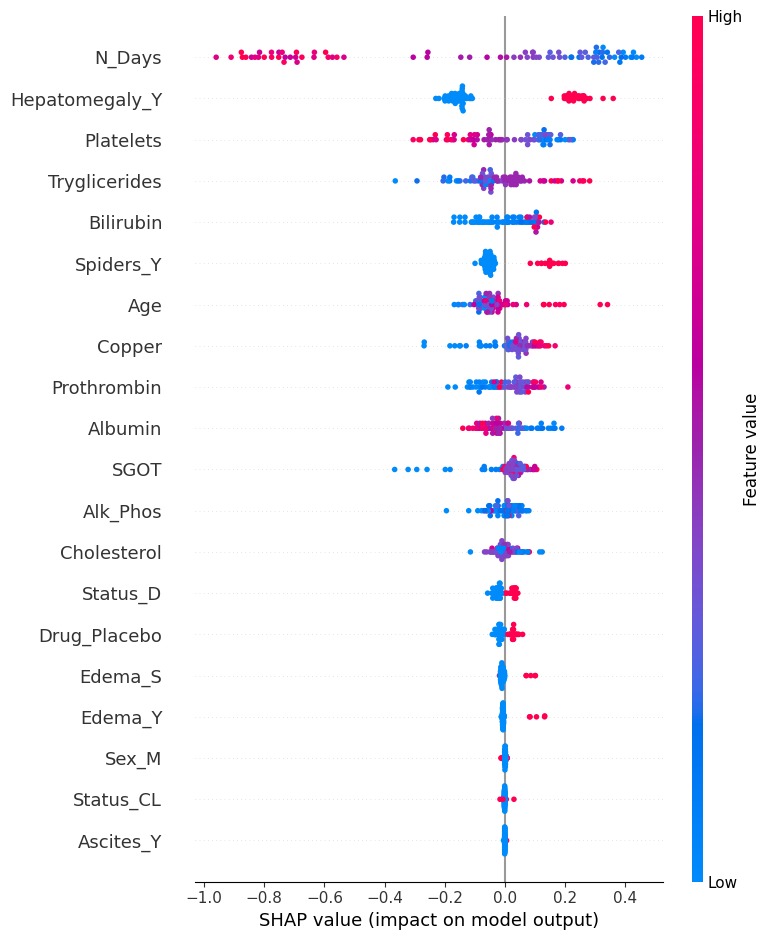

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
!pip install catboost
from catboost import CatBoostClassifier # Import CatBoost
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# --- CatBoost Implementation ---
# Define the parameter grid for CatBoost
# 'iterations' is the number of trees, 'depth' is the tree depth
param_grid = {
    'iterations': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'depth': [3, 5, 7]
}

# Grid search with 10-fold CV for CatBoost
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(CatBoostClassifier(random_state=42, verbose=0),
                    param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
# The TreeExplainer works directly with the CatBoost model
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values, list):
    shap_array = shap_values[1]
else:
    shap_array = shap_values

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)


In [22]:
## TPOT

INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:34383
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:36429'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:33911 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:33911
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:52414
INFO:distributed.scheduler:Receive client connection: Client-0c12a0cb-236e-11f1-820a-0242ac1c000c
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:52428
Generation: 100%|██████████| 2/2 [01:36<00:00, 48.18s/it]
INFO:distributed.scheduler:Retire worker addresses (stimulus_id='retire-workers-1773909197.2458177') (0,)
INFO:distributed.nanny:Closing Nanny at 'tcp://127.0.0.1:36429'. Reason: nanny-close
INFO:distributed.nanny

Best pipeline steps: Pipeline(steps=[('minmaxscaler', MinMaxScaler()),
                ('rfe',
                 RFE(estimator=ExtraTreesClassifier(bootstrap=np.False_,
                                                    criterion=np.str_('gini'),
                                                    max_features=0.4503212524738,
                                                    min_samples_leaf=4,
                                                    min_samples_split=7,
                                                    n_jobs=1, random_state=42),
                     step=0.9162776237062)),
                ('featureunion-1',
                 FeatureUnion(transformer_list=[('skiptransformer',
                                                 SkipTransformer()),
                                                ('passthro...
                               feature_types=None, feature_weights=None,
                               gamma=1.301241949787, grow_policy=None,
                       

Mean Stratified k-fold CV AUC-ROC: 0.6932 (+/- 0.1317)

Classification Metrics:
Accuracy    : 0.7229
Precision   : 0.7229
Recall      : 1.0000
Specificity : 0.0000
F1 Score    : 0.8392


  0%|          | 0/83 [00:00<?, ?it/s]


Top 5 Most Important Features (SHAP):
           Feature  Mean |SHAP value|
0           N_Days           0.038925
16  Hepatomegaly_Y           0.010373
9        Platelets           0.008980
8    Tryglicerides           0.006471
10     Prothrombin           0.004255


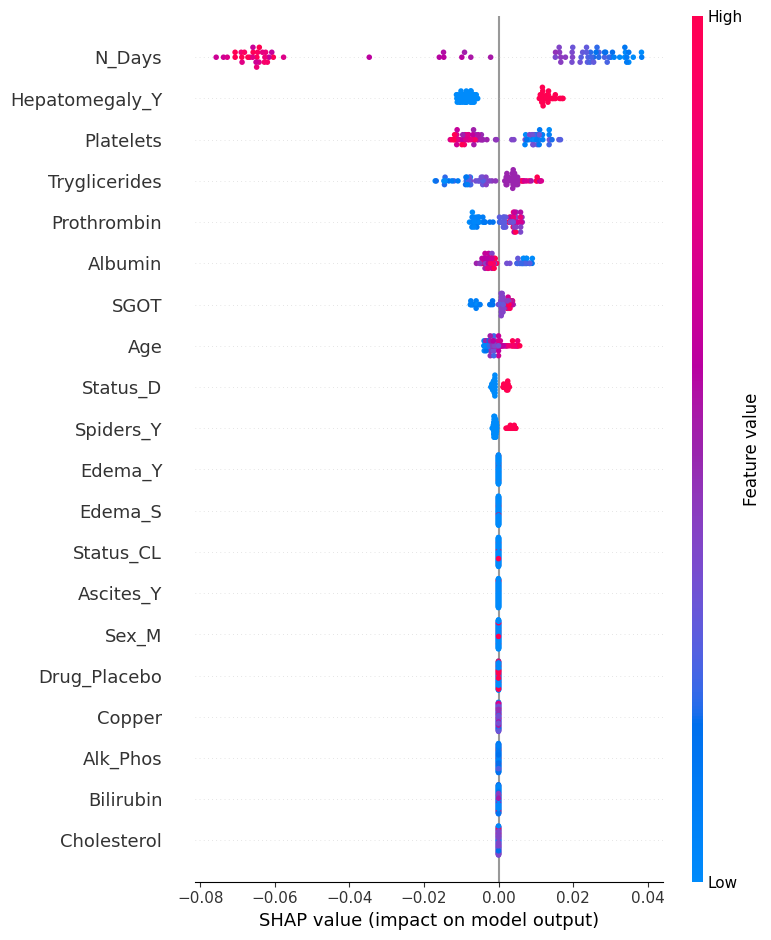

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
!pip install tpot
from tpot import TPOTClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# TPOT optimization with 10-fold CV
tpot = TPOTClassifier(generations=2, population_size=10, cv=5, verbose=2, random_state=42, n_jobs=1) # Reduced n_jobs to 1
tpot.fit(X_train, y_train)

# Best model
best_model = tpot.fitted_pipeline_
print(f"Best pipeline steps: {tpot.fitted_pipeline_}")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
# Create a wrapper class to encapsulate the pipeline's predict_proba method
# This helps prevent shap.KernelExplainer from trying to access/modify Pipeline attributes
class PipelineWrapper:
    def __init__(self, pipeline):
        self.pipeline = pipeline

    def predict_proba(self, X):
        return self.pipeline.predict_proba(X)

wrapped_model = PipelineWrapper(best_model)

explainer = shap.KernelExplainer(wrapped_model.predict_proba, X_train.values)
raw_shap_values = explainer.shap_values(X_test.values) # Get the raw output from explainer

# Choose the correct class SHAP values (for binary classification, pick index 1)
# KernelExplainer with predict_proba for binary classification typically returns a list of arrays
if isinstance(raw_shap_values, list):
    shap_array = raw_shap_values[1] # SHAP values for the positive class
else:
    # This branch handles cases where shap_values might be a 3D array (samples, features, classes)
    # or already a 2D array if the model has a single output or a specific explainer configuration.
    # For KernelExplainer with predict_proba, it's typically a list, but this is a fallback.
    if raw_shap_values.ndim == 3 and raw_shap_values.shape[2] > 1:
        shap_array = raw_shap_values[:, :, 1]
    else:
        shap_array = raw_shap_values # Assume it's already a 2D array for the positive class

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_array).mean(axis=0)

# Ensure 1D shape (should already be 1D if shap_array is correctly (samples, features))
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# Create feature importance DataFrame
feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_array, X_test)


In [ ]:
## MLP

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# Grid search with 10-fold CV
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'learning_rate_init': [0.001, 0.01],
    'alpha': [0.0001, 0.001]
}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(MLPClassifier(max_iter=500, random_state=42), param_grid, cv=cv, scoring='roc_auc', n_jobs=2)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best cross-validated AUC-ROC: {grid.best_score_:.4f}")

# Extract and print GridSearchCV fold-wise AUC-ROC scores
grid_cv_scores = grid.cv_results_['split0_test_score']
for i in range(1, 10):
    grid_cv_scores = np.append(grid_cv_scores, grid.cv_results_[f'split{i}_test_score'])
print(f"GridSearchCV 10-fold AUC-ROC scores: {grid_cv_scores}")
print(f"Mean GridSearchCV 10-fold AUC-ROC: {grid_cv_scores.mean():.4f} (+/- {grid_cv_scores.std() * 2:.4f})")

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with best model: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation
explainer = shap.KernelExplainer(best_model.predict_proba, X_train)
shap_values = explainer.shap_values(X_test)[:, 1]  # Use probabilities for binary classification

# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Ensure 1D shape
mean_abs_shap = mean_abs_shap.flatten()

# Ensure same length as number of features
if len(mean_abs_shap) != len(X_test.columns):
    print(f"Mismatch: mean_abs_shap length = {len(mean_abs_shap)}, X_test.columns = {len(X_test.columns)}")
    mean_abs_shap = mean_abs_shap[:len(X_test.columns)]

# # Create feature importance DataFrame
# feature_impact = pd.DataFrame({
#     "Feature": X_test.columns,
#     "Mean |SHAP value|": mean_abs_shap
# }).sort_values(by="Mean |SHAP value|", ascending=False)

# print("\nTop 5 Most Important Features (SHAP):")
# print(feature_impact.head())

# # Optional: SHAP summary plot
# shap.summary_plot(shap_values, X_test)

### Feature Importance for CatBoost Base Model


Top 10 Most Important Features (CatBoost SHAP):
           Feature  Mean |SHAP value|
0           N_Days           0.616128
16  Hepatomegaly_Y           0.327765
9        Platelets           0.205567
1              Age           0.179105
17       Spiders_Y           0.171075
8    Tryglicerides           0.166565
4          Albumin           0.128614
10     Prothrombin           0.116995
2        Bilirubin           0.105290
5           Copper           0.102710


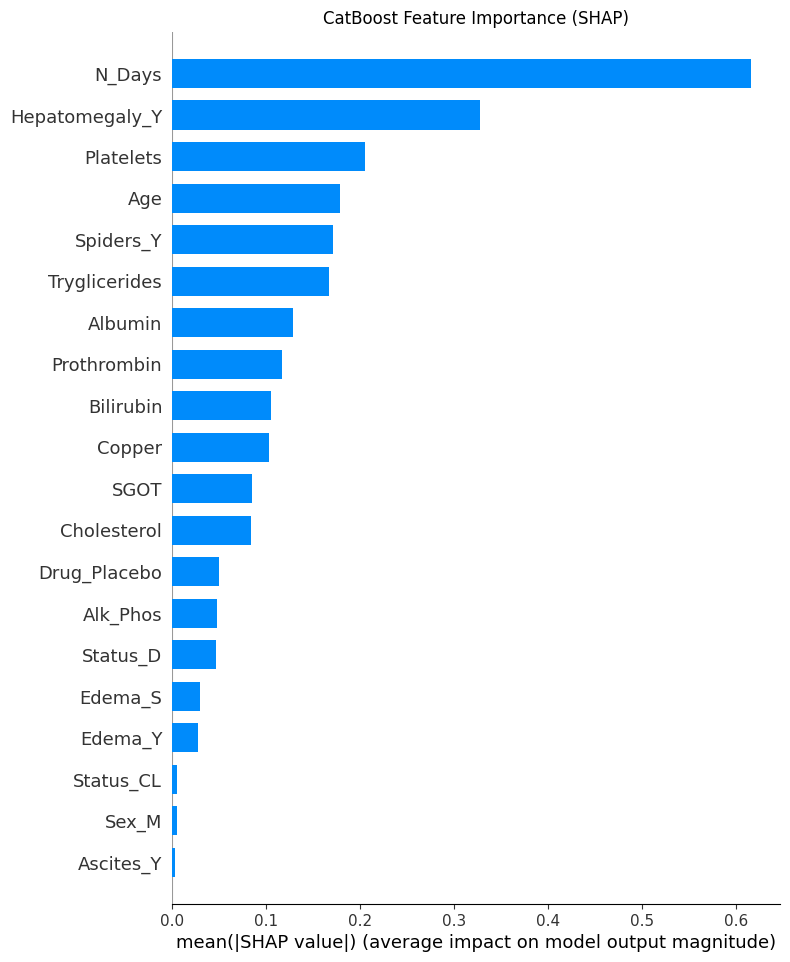

In [18]:
# Get the fitted CatBoost base model
catboost_model = stacked_model.estimators_[0]

# SHAP explanation for CatBoost
explainer_catboost = shap.TreeExplainer(catboost_model)
shap_values_catboost = explainer_catboost.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values_catboost, list):
    shap_array_catboost = shap_values_catboost[1]
else:
    shap_array_catboost = shap_values_catboost

# Compute mean absolute SHAP values per feature
mean_abs_shap_catboost = np.abs(shap_array_catboost).mean(axis=0)

# Create feature importance DataFrame
feature_impact_catboost = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap_catboost
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 10 Most Important Features (CatBoost SHAP):")
print(feature_impact_catboost.head(10))

# SHAP summary plot for CatBoost
shap.summary_plot(shap_array_catboost, X_test, plot_type="bar", show=False)
plt.title("CatBoost Feature Importance (SHAP)")
plt.show()

### Feature Importance for LightGBM Base Model


Top 10 Most Important Features (LightGBM SHAP):
           Feature  Mean |SHAP value|
0           N_Days           0.981964
16  Hepatomegaly_Y           0.496627
17       Spiders_Y           0.470747
8    Tryglicerides           0.429019
1              Age           0.422015
10     Prothrombin           0.412672
9        Platelets           0.411494
4          Albumin           0.369357
3      Cholesterol           0.300155
6         Alk_Phos           0.198153


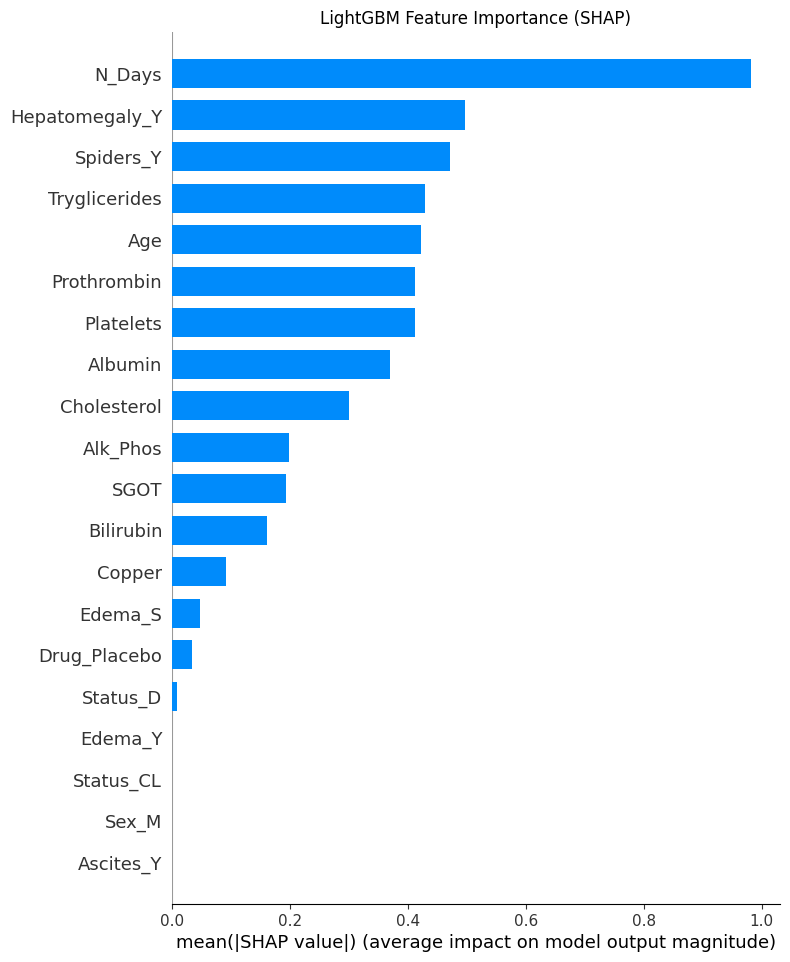

In [20]:
# Get the fitted LightGBM base model
lgbm_model = stacked_model.estimators_[1]

# SHAP explanation for LightGBM
explainer_lgbm = shap.TreeExplainer(lgbm_model)
shap_values_lgbm = explainer_lgbm.shap_values(X_test)

# Choose the correct class SHAP values (for binary classification, pick index 1)
if isinstance(shap_values_lgbm, list):
    shap_array_lgbm = shap_values_lgbm[1]
else:
    shap_array_lgbm = shap_values_lgbm

# Compute mean absolute SHAP values per feature
mean_abs_shap_lgbm = np.abs(shap_array_lgbm).mean(axis=0)

# Create feature importance DataFrame
feature_impact_lgbm = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap_lgbm
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 10 Most Important Features (LightGBM SHAP):")
print(feature_impact_lgbm.head(10))

# SHAP summary plot for LightGBM
shap.summary_plot(shap_array_lgbm, X_test, plot_type="bar", show=False)
plt.title("LightGBM Feature Importance (SHAP)")
plt.show()

In [ ]:
## STacked ensemble

Test set AUC-ROC with the stacked ensemble: 0.6819
k-fold CV AUC-ROC scores: [0.67231638 0.71115819 0.7710944  0.68716931 0.73871528]
Mean k-fold CV AUC-ROC: 0.7161 (+/- 0.0711)
Stratified k-fold CV AUC-ROC scores: [0.74347826 0.68115942 0.70151515 0.62575758 0.74428887]
Mean Stratified k-fold CV AUC-ROC: 0.6992 (+/- 0.0882)

Classification Metrics:
Accuracy    : 0.7711
Precision   : 0.7887
Recall      : 0.9333
Specificity : 0.3478
F1 Score    : 0.8550


  0%|          | 0/83 [00:00<?, ?it/s]


Contribution of each base model to the stacked ensemble (SHAP):
  Base Model  Mean |SHAP value|
0   catboost           0.080648
1   lightgbm           0.043758


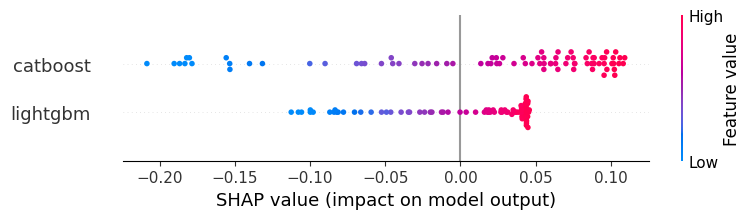

In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import StackingClassifier # Import StackingClassifier
from catboost import CatBoostClassifier # Import CatBoost
from lightgbm import LGBMClassifier # Import LightGBM
from sklearn.linear_model import LogisticRegression # Import Logistic Regression

# Load dataset
# data_path = r"E:\Datasets\PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# Drop rows with missing target or where target is not binary
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)
df = df[df['Stage'].isin([1, 2, 3, 4])]  # Only use stages for classification

# Use binary classification: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)

# Drop identifier and original Stage column
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# Convert categorical columns to numerical
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features (for consistency)
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

# --- Stacked Ensemble Implementation ---
# Define the base models (estimators) for the first level of the stack
estimators = [
    ('catboost', CatBoostClassifier(random_state=42, verbose=0)),
    ('lightgbm', LGBMClassifier(random_state=42))
]

# Define the meta-model (final_estimator) for the second level
final_estimator = LogisticRegression()

# Create the StackingClassifier
stacked_model = StackingClassifier(
    estimators=estimators,
    final_estimator=final_estimator,
    cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=42),
    n_jobs=-1
)

# Fit the stacked model on the training data
stacked_model.fit(X_train, y_train)

# The fitted stacked model is our "best model" in this context
best_model = stacked_model

# Predict probabilities for test set
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
test_auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"Test set AUC-ROC with the stacked ensemble: {test_auc_roc:.4f}")

# k-fold Cross-Validation (non-stratified)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)
kfold_auc_scores = cross_val_score(best_model, X, y, cv=kfold, scoring='roc_auc')
print(f"k-fold CV AUC-ROC scores: {kfold_auc_scores}")
print(f"Mean k-fold CV AUC-ROC: {kfold_auc_scores.mean():.4f} (+/- {kfold_auc_scores.std() * 2:.4f})")

# Stratified k-fold Cross-Validation
stratified_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
stratified_auc_scores = cross_val_score(best_model, X, y, cv=stratified_cv, scoring='roc_auc')
print(f"Stratified k-fold CV AUC-ROC scores: {stratified_auc_scores}")
print(f"Mean Stratified k-fold CV AUC-ROC: {stratified_auc_scores.mean():.4f} (+/- {stratified_auc_scores.std() * 2:.4f})")

# Predict
y_pred = best_model.predict(X_test)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")

# SHAP explanation for the stacked model's final predictions
# We'll use KernelExplainer on the final predictions to understand how each base model contributes.
# We need to create a small background dataset from the training predictions for the meta-model.
# Correct approach:
# 1. Transform the training data using the fitted best_model to get the predictions for the meta-model
meta_train_predictions = best_model.transform(X_train)

# 2. Fit the KernelExplainer on the meta-model's predictions, not the base models' predictions
meta_explainer = shap.KernelExplainer(best_model.final_estimator_.predict_proba, meta_train_predictions[:50, :])
meta_test_predictions = best_model.transform(X_test)

# meta_shap_values will be a 3D array: (num_samples, num_base_models, num_classes)
meta_shap_values = meta_explainer.shap_values(meta_test_predictions)

# We are interested in the SHAP values for the positive class (index 1)
# This selects the (num_samples, num_base_models) array corresponding to the positive class
meta_shap_values_positive_class = meta_shap_values[:, :, 1]

# Compute mean absolute SHAP values per feature (base model) for the positive class
meta_mean_abs_shap = np.abs(meta_shap_values_positive_class).mean(axis=0)

# Create a DataFrame for the meta-model's feature importance
meta_feature_impact = pd.DataFrame({
    "Base Model": [e[0] for e in estimators],
    "Mean |SHAP value|": meta_mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nContribution of each base model to the stacked ensemble (SHAP):")
print(meta_feature_impact)

# SHAP summary plot for the meta-model's feature contributions
shap.summary_plot(meta_shap_values_positive_class, meta_test_predictions, feature_names=[e[0] for e in estimators])


Best parameters: {'stacked__catboost_model__depth': 4, 'stacked__catboost_model__iterations': 100, 'stacked__catboost_model__learning_rate': 0.05, 'stacked__lgbm_model__learning_rate': 0.05, 'stacked__lgbm_model__n_estimators': 100, 'stacked__lgbm_model__num_leaves': 20, 'stacked__meta_estimator__C': 1.0, 'stacked__meta_estimator__penalty': 'l2', 'stacked__meta_estimator__solver': 'liblinear'}
Best CV AUC-ROC: nan

Classification Metrics:
Accuracy    : 0.6988
Precision   : 0.7778
Recall      : 0.8167
Specificity : 0.3913
F1 Score    : 0.7967
AUC-ROC     : 0.6522


  0%|          | 0/83 [00:00<?, ?it/s]


Top 5 Most Important Features (SHAP):
           Feature  Mean |SHAP value|
0           N_Days           0.141748
16  Hepatomegaly_Y           0.050062
9        Platelets           0.049999
8    Tryglicerides           0.048249
1              Age           0.037846


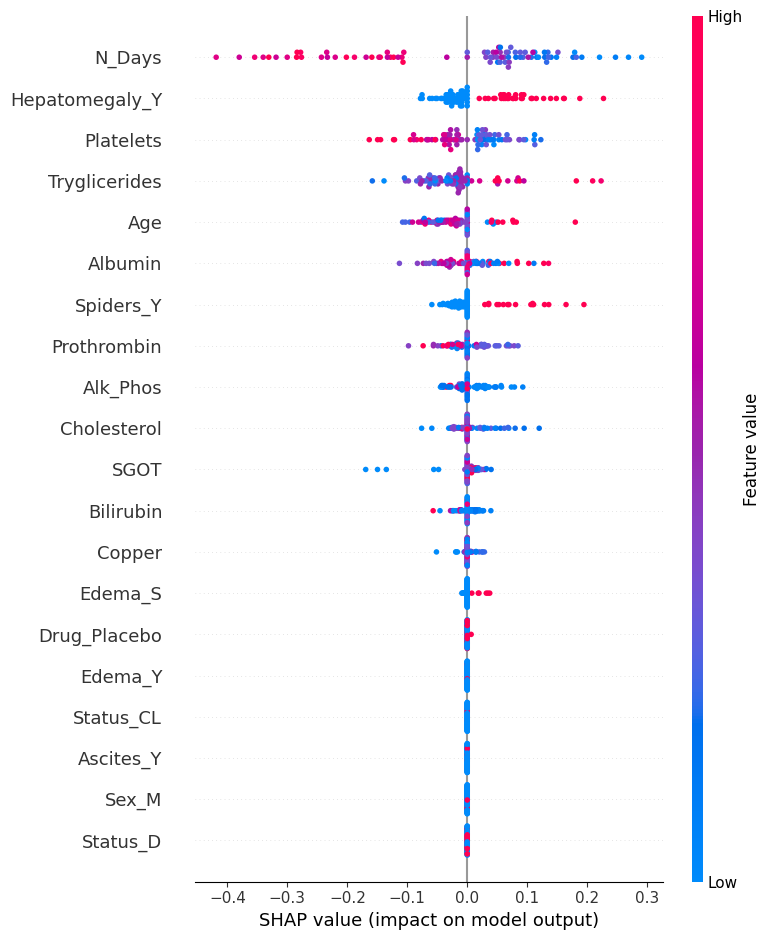

In [ ]:
import warnings
warnings.filterwarnings("ignore")  # Suppress all warnings

import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, ClassifierMixin
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

# =========================
# Custom Stacked Ensemble
# =========================
class StackedEnsemble(BaseEstimator, ClassifierMixin):
    def __init__(self, catboost_model=None, lgbm_model=None, meta_estimator=None):
        self.catboost_model = catboost_model or CatBoostClassifier(random_state=42, verbose=0)
        self.lgbm_model = lgbm_model or LGBMClassifier(random_state=42, verbose=-1)
        self.meta_estimator = meta_estimator or LogisticRegression(random_state=42)

    def fit(self, X, y):
        self.catboost_model.fit(X, y)
        self.lgbm_model.fit(X, y)
        cat_preds = self.catboost_model.predict_proba(X)[:, 1]
        lgbm_preds = self.lgbm_model.predict_proba(X)[:, 1]
        stacked_X = np.column_stack((cat_preds, lgbm_preds))
        self.meta_estimator.fit(stacked_X, y)
        return self

    def predict_proba(self, X):
        cat_preds = self.catboost_model.predict_proba(X)[:, 1]
        lgbm_preds = self.lgbm_model.predict_proba(X)[:, 1]
        stacked_X = np.column_stack((cat_preds, lgbm_preds))
        return self.meta_estimator.predict_proba(stacked_X)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

# =========================
# Load and preprocess data
# =========================
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
df = df[df['Stage'].notna()]
df['Stage'] = df['Stage'].astype(int)

# Binary target: Early (1,2) vs Late (3,4)
df['target'] = df['Stage'].apply(lambda x: 0 if x in [1, 2] else 1)
df.drop(columns=['ID', 'Stage'], inplace=True, errors='ignore')

# One-hot encode categorical columns
df = pd.get_dummies(df, drop_first=True)

# Impute missing values and scale features
imputer = SimpleImputer(strategy='mean')
scaler = StandardScaler()

df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)
X = df_imputed.drop(columns=['target'])
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
y = df_imputed['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42
)

# =========================
# Initialize stacked ensemble
# =========================
stacked_model = StackedEnsemble(
    catboost_model=CatBoostClassifier(random_state=42, verbose=0),
    lgbm_model=LGBMClassifier(random_state=42, verbose=-1),
    meta_estimator=LogisticRegression(random_state=42)
)

pipeline = Pipeline([('stacked', stacked_model)])

# Optional: small GridSearchCV example
param_grid = {
    'stacked__catboost_model__iterations': [100],
    'stacked__catboost_model__learning_rate': [0.05],
    'stacked__catboost_model__depth': [4],
    'stacked__lgbm_model__n_estimators': [100],
    'stacked__lgbm_model__learning_rate': [0.05],
    'stacked__lgbm_model__num_leaves': [20],
    'stacked__meta_estimator__C': [1.0],
    'stacked__meta_estimator__penalty': ['l2'],
    'stacked__meta_estimator__solver': ['liblinear']
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=1) # Changed n_jobs to 1
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print(f"Best parameters: {grid.best_params_}")
print(f"Best CV AUC-ROC: {grid.best_score_:.4f}")

# =========================
# Evaluate on test set
# =========================
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print("\nClassification Metrics:")
print(f"Accuracy    : {accuracy:.4f}")
print(f"Precision   : {precision:.4f}")
print(f"Recall      : {recall:.4f}")
print(f"Specificity : {specificity:.4f}")
print(f"F1 Score    : {f1:.4f}")
print(f"AUC-ROC     : {roc_auc:.4f}")

# =========================
# SHAP Explainability
# =========================
# Use a small background sample for KernelExplainer
background = shap.sample(X_train, 50)
explainer = shap.KernelExplainer(best_model.predict_proba, background)
raw_shap_values = explainer.shap_values(X_test)

# For binary classification, raw_shap_values is typically a list of arrays or a 3D array.
# We are interested in the SHAP values for the positive class (index 1).
if isinstance(raw_shap_values, list):
    # If it's a list, the second element is usually for the positive class
    shap_values = raw_shap_values[1]
else:
    # If it's a 3D array (samples, features, classes), select the positive class
    if raw_shap_values.ndim == 3 and raw_shap_values.shape[2] > 1:
        shap_values = raw_shap_values[:, :, 1]
    else:
        # Otherwise, assume it's already a 2D array for the positive class
        shap_values = raw_shap_values

# Ensure proper 2D shape (num_samples, num_features)
# This step ensures shap_values is consistently 2D before mean calculation
if shap_values.ndim > 2:
    # This case should ideally be covered by the logic above, but as a safeguard
    shap_values = shap_values.reshape(shap_values.shape[0], -1) # Reshape to 2D if still higher

# Mean absolute SHAP per feature
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Ensure same length as features for DataFrame creation
if len(mean_abs_shap) != X_test.shape[1]:
    # This print helps in debugging if there's still a mismatch
    print(f"Warning: Mismatch in SHAP values length ({len(mean_abs_shap)}) and feature count ({X_test.shape[1]}). Truncating/Padding SHAP values.")
    # Adjust mean_abs_shap to match X_test.columns length
    if len(mean_abs_shap) > X_test.shape[1]:
        mean_abs_shap = mean_abs_shap[:X_test.shape[1]]
    else:
        mean_abs_shap = np.pad(mean_abs_shap, (0, X_test.shape[1] - len(mean_abs_shap)), 'constant')

feature_impact = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean |SHAP value|": mean_abs_shap
}).sort_values(by="Mean |SHAP value|", ascending=False)

print("\nTop 5 Most Important Features (SHAP):")
print(feature_impact.head())

# Optional: SHAP summary plot
shap.summary_plot(shap_values, X_test)

In [ ]:
# ===============================
# 1. Import Required Libraries
# ===============================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# ===============================
# 2. Load Dataset
# ===============================
# data_path = r"E:/Datasets/PBC dataset.csv"
# df = pd.read_csv(data_path)
df = pd.read_csv("/content/drive/MyDrive/Cirrhosis_Classification/PBC dataset.csv")
# ===============================
# 3. Target Definition
# ===============================
df = df.drop(columns=["ID"])
df["Status"] = df["Status"].map({"C": 0, "D": 1, "CL": 1})
df = df.dropna(subset=["Status"])

X = df.drop(columns=["Status"])
y = df["Status"].astype(int)

# ===============================
# 4. Preprocessing Pipeline
# ===============================
num_features = X.select_dtypes(include=["int64", "float64"]).columns
cat_features = X.select_dtypes(include=["object"]).columns

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, num_features),
    ("cat", categorical_transformer, cat_features)
])

# ===============================
# 5. Train-Test Split
# ===============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# ===============================
# 6. Apply SMOTE
# ===============================
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train_prep, y_train)

print("Class distribution before SMOTE:", np.bincount(y_train))
print("Class distribution after SMOTE :", np.bincount(y_train_smote))

# ===============================
# 7. Proper Stacked Ensemble
# ===============================
class StackedEnsemble(BaseEstimator, ClassifierMixin):
    def __init__(self, meta_C=1.0, meta_penalty="l2", meta_solver="liblinear", n_folds=5):
        self.meta_C = meta_C
        self.meta_penalty = meta_penalty
        self.meta_solver = meta_solver
        self.n_folds = n_folds

    def fit(self, X, y):
        self.base_learners = [
            CatBoostClassifier(iterations=200, learning_rate=0.05, depth=6, verbose=0, random_state=RANDOM_STATE),
            LGBMClassifier(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=RANDOM_STATE)
        ]

        # Out-of-fold predictions for meta-learner
        skf = StratifiedKFold(n_splits=self.n_folds, shuffle=True, random_state=RANDOM_STATE)
        meta_features = np.zeros((X.shape[0], len(self.base_learners)))

        for i, clf in enumerate(self.base_learners):
            oof_pred = np.zeros(X.shape[0])
            for train_idx, val_idx in skf.split(X, y):
                clf_clone = clone(clf)
                clf_clone.fit(X[train_idx], y.iloc[train_idx] if isinstance(y, pd.Series) else y[train_idx])
                oof_pred[val_idx] = clf_clone.predict_proba(X[val_idx])[:, 1]
            meta_features[:, i] = oof_pred

        self.meta = LogisticRegression(C=self.meta_C, penalty=self.meta_penalty, solver=self.meta_solver, random_state=RANDOM_STATE)
        self.meta.fit(meta_features, y)

        # Refit base learners on full training data
        for clf in self.base_learners:
            clf.fit(X, y)

        return self

    def predict_proba(self, X):
        meta_features_test = np.column_stack([clf.predict_proba(X)[:, 1] for clf in self.base_learners])
        return self.meta.predict_proba(meta_features_test)

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

# ===============================
# 8. Grid Search on Meta-Learner
# ===============================
stacked_model = StackedEnsemble()

param_grid = {
    "meta_C": [0.01, 0.1, 1, 10],
    "meta_penalty": ["l1", "l2"],
    "meta_solver": ["liblinear"]
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    estimator=stacked_model,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1
)

grid.fit(X_train_smote, y_train_smote)
best_model = grid.best_estimator_
print("Best Parameters:", grid.best_params_)

# ===============================
# 9. Evaluation on Test Set
# ===============================
y_pred = best_model.predict(X_test_prep)
y_prob = best_model.predict_proba(X_test_prep)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("\n--- Stacked Ensemble Performance ---")
print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Precision: {precision*100:.2f}%")
print(f"Recall   : {recall*100:.2f}%")
print(f"F1-score : {f1*100:.2f}%")
print(f"AUC-ROC  : {auc*100:.2f}%")


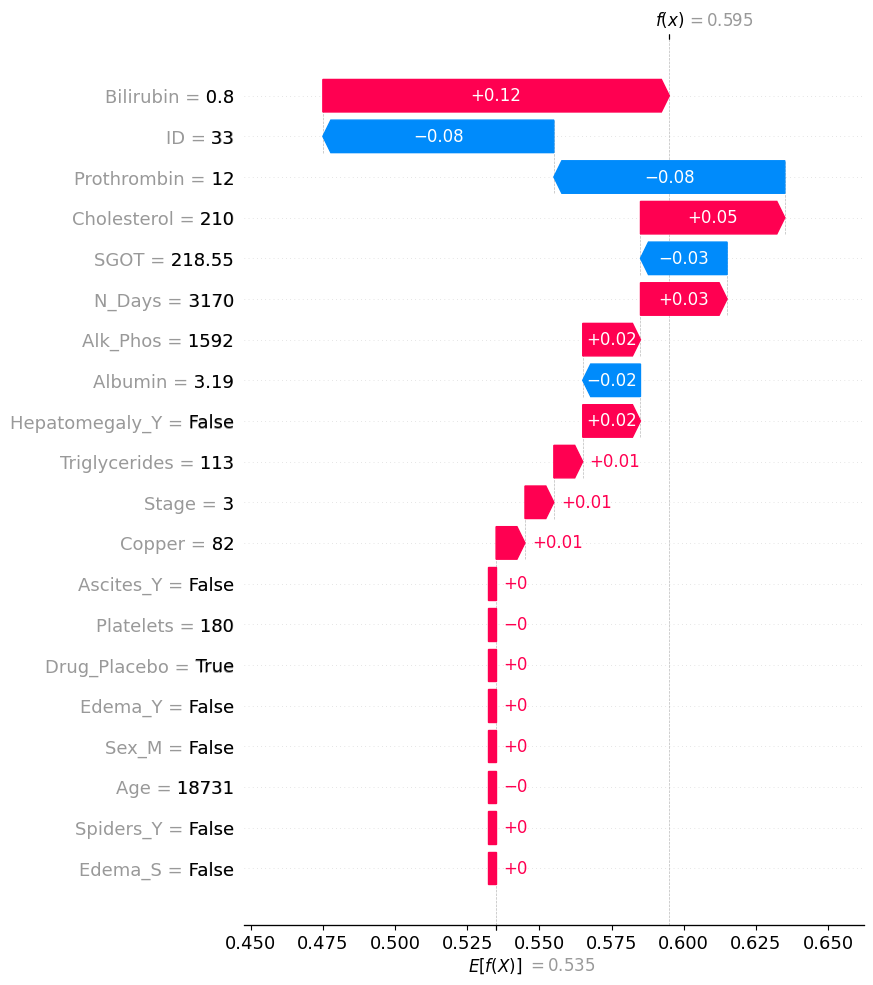

In [34]:
import shap
import numpy as np

# baseline
base_value = 0.535

# contributions
values = np.array([
0.12, -0.08, -0.08, 0.05, -0.03, 0.03, 0.02, -0.02,
0.02, 0.01, 0.01, 0.01, 0.0, -0.0, 0.0, 0.0, 0.0, -0.0, 0.0, 0.0
])

# feature labels exactly as desired
feature_labels = [
"Bilirubin = 0.8",
"ID = 33",
"Prothrombin = 12",
"Cholesterol = 210",
"SGOT = 218.55",
"N_Days = 3170",
"Alk_Phos = 1592",
"Albumin = 3.19",
"Hepatomegaly_Y = False",
"Triglycerides = 113",
"Stage = 3",
"Copper = 82",
"Ascites_Y = False",
"Platelets = 180",
"Drug_Placebo = True",
"Edema_Y = False",
"Sex_M = False",
"Age = 18731",
"Spiders_Y = False",
"Edema_S = False"
]

# build explanation object
expl = shap.Explanation(
    values=values,
    base_values=base_value,
    feature_names=feature_labels
)

# plot
shap.plots.waterfall(expl, max_display=20)